# B2B Score — Buy-Outcome Backtest  (Existing vs Peer-Cohort, judged by real prepayments)

**The question, in the B2B team's words:** *If we had used the Peer-Cohort score last year,
would the loans we actually bought have performed better than the ones the Existing score
led us to?*

**Why this is trustworthy.** We run BOTH scores at points in the past, let each drive the
real buy rule, then watch what the loans **actually did**. The referee is **realized
prepayment (principal run-off)** — a number neither score can influence.

**How it works (plain English).**
1. Pick a series of decision dates in the past (**month-ends Jan–Jun 2025**).
2. On each date, score every client **two ways** — Existing (pricing-model) and
   Peer-Cohort — using only data up to that date, tag each **Favourable / Neutral /
   Unfavourable** (0.8 / 1.2 cut-offs).
3. Apply the real buy rule: buy everything from Favourable + Neutral, cap the
   **Unfavourable segment at ≤ 20% of the month's dollar volume** (aggregate $ cap).
4. Watch what those loans did over the next 6 months — from principal balances.
5. Compare the two "what-if" books, and look hard at the clients where the scores **disagree**.

**Results map 1:1 to the Go/No-Go deck:**
* **Result A** → *Slide 4* — the bought book (realized prepay + retained $/100 + win-rate).
* **Result B** → *Slide 5 (context)* — disagreement groups (hidden risk vs false alarm).
* **Result C** → *Slide 5 (the deciding test)* — the **rate-SPREAD** control: within each
  `Rate − Market_Rate` band, do the flagged loans still prepay faster? This is the
  peer-fair test — it isolates real risk from simply holding high-rate loans.

Run top-to-bottom. Everything you might change lives in the **USER INPUTS** cell.
Use the **`Python (B2B)`** kernel; place this file where the `functions/` folder (with
**both** `B2B_functions_monthly_report.py` and `B2B_functions_cohort_score.py`) is importable.

## 0. USER INPUTS  —  the only cell you normally edit

In [1]:
from datetime import date
import os, calendar

# ── DECISION DATES ────────────────────────────────────────────────────────────
DECISION_START = date(2025, 6, 30)   # first decision month-end
DECISION_END   = date(2025, 11, 30)   # last  decision month-end (each watched 6 mo fwd)

# ── FORWARD HORIZON ───────────────────────────────────────────────────────────
FORWARD_MONTHS  = 6      # months of REAL prepayment we watch after each decision date
MIN_FWD_MONTHS  = 4      # a client needs at least this many forward months to be scored

# ── CRT POLICY ────────────────────────────────────────────────────────────────
FAV_THRESHOLD   = 1.2    # B2B Score >  1.2  → Favourable
UNFAV_THRESHOLD = 0.8    # B2B Score <  0.8  → Unfavourable  (in-between = Neutral)
CAP_UNFAV_SHARE = 0.20   # AGGREGATE $ cap: Unfavourable ≤ 20% of the month's purchases

# ── RATE-SPREAD CONTROL (Result C) ────────────────────────────────────────────
# The deciding, peer-fair test bands loans by RATE SPREAD = Note Rate − Market Rate.
# Market_Rate is pulled per (AsofDt, LoanNum) from Analytics_Rpt.md.B2B_revamp_cohorts.
# Spread is in decimal (0.005 = 0.5%). Edit the band edges to taste. Note: -0.05 = -5%
SPREAD_BINS   = [-10.0, -0.01, -0.005, 0.0, 0.005, 0.010, 0.015, 0.02, 0.025, 10.0]
SPREAD_LABELS = ['≤ -1%', '-1–-0.5%', '-0.5–0%', '0–0.5%', '0.5–1.0%', '1.0–1.5%', '1.5–2.0%', '2.0–2.5%', '2.5%+']

# ── SQL CONNECTION  (same as the reporting notebooks) ─────────────────────────
SQL_SERVER   = 'VMC2VMDBRADC01P'
SQL_DATABASE = 'Analytics_Rpt'
SQL_DRIVER   = 'ODBC Driver 17 for SQL Server'

# ── FILE PATHS  (company laptop, Windows) ─────────────────────────────────────
BACKTEST_DIR = r"E:\Development\Shashi\B2B-Pricing-Model\Cohort_Analysis\B2B_backtest"
CACHE_FILE   = os.path.join(BACKTEST_DIR, "b2b_backtest_cache.pkl")

# ── RUN CONTROL ───────────────────────────────────────────────────────────────
# True    = full pull for every decision date, then overwrite the cache from scratch.
# False   = no SQL at all — load whatever is already in the cache (fast re-plots).
# "REUSE" = SMART INCREMENTAL: load the cache, pull ONLY the dates/fields/forward-months
#           that are missing, merge, and save. Use this after adding new decision dates
#           (or after adding the new rate-spread field) so you don't re-pull everything.
RUN_SCORING = "REUSE"

os.makedirs(BACKTEST_DIR, exist_ok=True)
print("Decision dates :", DECISION_START, "->", DECISION_END,
      f"| watch {FORWARD_MONTHS} months forward")
print("Aggregate cap  :", f"{CAP_UNFAV_SHARE:.0%} of monthly $ from Unfavourable segment")
print("Cache file     :", CACHE_FILE, "| RUN_SCORING =", RUN_SCORING)

Decision dates : 2025-06-30 -> 2025-11-30 | watch 6 months forward
Aggregate cap  : 20% of monthly $ from Unfavourable segment
Cache file     : E:\Development\Shashi\B2B-Pricing-Model\Cohort_Analysis\B2B_backtest\b2b_backtest_cache.pkl | RUN_SCORING = REUSE


## 1. Imports, connection & both scorers

In [2]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sqlalchemy import text
%matplotlib inline

FUNCTIONS_DIR = os.path.join(os.getcwd(), 'functions')
if FUNCTIONS_DIR not in sys.path:
    sys.path.insert(0, FUNCTIONS_DIR)

# BOTH scorers live in functions/ under the SAME class name, so we alias them.
from B2B_functions_cohort_score  import sql_connection, B2BPricingReporter as PeerReporter    # Peer-Cohort (new)
from B2B_functions_monthly_report import B2BPricingReporter as ExistingReporter               # Existing (old)

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 170)
plt.rcParams['figure.figsize'] = (9, 4.4)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

engine = sql_connection(server=SQL_SERVER, database=SQL_DATABASE, driver=SQL_DRIVER)
print("Connected:", engine.url.database)
engine

Connected: 


Engine(mssql+pyodbc:///?odbc_connect=DRIVER%3D%7BODBC+Driver+17+for+SQL+Server%7D%3BSERVER%3DVMC2VMDBRADC01P%3BDATABASE%3DAnalytics_Rpt%3BTrusted_Connection%3Dyes)

## 2. Date helpers

* `trailing_fund_window(T)` — the Existing score's 12-month origination window ending at
  `T` (matches your example: `T = 31-Jul-2025` → `1-Aug-2024 .. 31-Jul-2025`).
* `forward_month_ends(T, k)` — the `k` month-ends *after* `T` (the out-of-sample window).

In [3]:
def month_ends(a: date, b: date):
    outs, y, m = [], a.year, a.month
    while True:
        d = date(y, m, calendar.monthrange(y, m)[1])
        if d > b: break
        outs.append(d)
        y, m = (y + 1, 1) if m == 12 else (y, m + 1)
    return outs

def month_start(T: date) -> date:
    return date(T.year, T.month, 1)

def trailing_fund_window(T: date):
    tot = (T.year * 12 + (T.month - 1)) - 11
    by, bm = divmod(tot, 12)
    return date(by, bm + 1, 1), T

def forward_month_ends(T: date, k: int):
    outs, y, m = [], T.year, T.month
    for _ in range(k):
        y, m = (y + 1, 1) if m == 12 else (y, m + 1)
        outs.append(date(y, m, calendar.monthrange(y, m)[1]))
    return outs

DECISION_DATES = month_ends(DECISION_START, DECISION_END)
print("Decision dates:", [str(d) for d in DECISION_DATES])

Decision dates: ['2025-06-30', '2025-07-31', '2025-08-31', '2025-09-30', '2025-10-31', '2025-11-30']


## 3. The four pulls

* **`score_existing(T)`** / **`score_peer(T)`** — each client's B2B score, both ways, as of `T`.
* **`buy_volume(T)`** — dollars funded in the decision month = the purchasable universe.
* **`rate_spread_by_client(T)`** — each client's dollar-weighted **Rate − Market_Rate** as
  of `T`, with `Market_Rate` joined from `Analytics_Rpt.md.B2B_revamp_cohorts` on
  `(AsofDt, LoanNum)`. Used only by the Result C rate-spread control.
* **`outcome_runoff(begin, end)`** — monthly principal balances per client (the referee).

In [31]:
def score_existing(T: date) -> pd.DataFrame:
    bf_, ef_ = trailing_fund_window(T)
    rep = ExistingReporter(engine).load(begin_score_dt=None, end_score_dt=T,
                                        begin_fund_dt=bf_, end_fund_dt=ef_)
    df = rep.build_groupby_summary(['Client'])
    return df[['Client', 'TotalScore', 'WAC']].rename(columns={'TotalScore': 'score_existing'})

def score_peer(T: date) -> pd.DataFrame:
    rep = PeerReporter(engine).load(report_as_of_dt=T)
    df = rep.build_groupby_summary(['Client'])
    return df[['Client', 'TotalScore']].rename(columns={'TotalScore': 'score_peer'})

def buy_volume(T: date) -> pd.Series:
    vol = ExistingReporter(engine).build_volume_summary_all(month_start(T), T)
    return vol.groupby('Client')['FundedLoanAmt'].sum()

def rate_spread_by_client(T: date) -> pd.DataFrame:
    # Dollar-weighted (Rate − Market_Rate) per client, sourced entirely from
    # B2B_revamp_cohorts so the loan universe and rate definition are consistent.
    # Both IntRate and Market_Rate are stored as PERCENTAGE (e.g. 6.565 = 6.565%).
    # Divide by 100 so the returned spread is in DECIMAL to match SPREAD_BINS.
    sql = text('''
        SELECT a.Client, a.LoanNum, a.BeginPrinBal,
               c.IntRate, c.Market_Rate
        FROM Analytics_Rpt.md.B2BPricingHist a
        LEFT JOIN Analytics_Rpt.md.B2B_revamp_cohorts c
               ON c.LoanNum = a.LoanNum AND c.AsofDt = a.AsofDt
        WHERE a.AsofDt = :asof
          AND a.FundedLoanAmt > 0
          AND NOT EXISTS (SELECT 1 FROM Analytics_Rpt.md.B2BPricingHist x
                          WHERE x.LoanNum = a.LoanNum
                            AND (x.ResolType = \'XFER\' OR x.Channel = \'Bulk\'))
    ''')
    df = pd.read_sql(sql, engine, params={'asof': T})
    int_rate = pd.to_numeric(df['IntRate'],     errors='coerce')
    mkt_rate = pd.to_numeric(df['Market_Rate'], errors='coerce')
    df['spread'] = (int_rate - mkt_rate) / 100   # % → decimal
    w = pd.to_numeric(df['BeginPrinBal'], errors='coerce').fillna(0)
    df = df[df['spread'].notna() & (w > 0)].copy()
    df['_w'] = w; df['_ws'] = df['spread'] * w
    g = df.groupby('Client').agg(_ws=('_ws', 'sum'), _w=('_w', 'sum'))
    g['spread'] = np.where(g['_w'] > 0, g['_ws'] / g['_w'], np.nan)
    return g.reset_index()[['Client', 'spread']]

def outcome_runoff(begin: date, end: date) -> pd.DataFrame:
    perf = ExistingReporter(engine).build_perform_summary_all(begin, end)
    r = (perf.groupby(['Client', 'AsofDt'], dropna=False)
             .agg(Begin=('BeginPrinBal', 'sum'), End=('EndPrinBal', 'sum'))
             .reset_index())
    r['AsofDt'] = pd.to_datetime(r['AsofDt'])
    return r


## 4. Run the pulls — with smart caching

`RUN_SCORING` controls how much SQL runs:

| value | behaviour |
|---|---|
| `True` | full pull for every decision date, overwrite the cache |
| `False` | **no SQL** — load whatever is in the cache (fast re-plots) |
| `"REUSE"` | **incremental** — load the cache, pull only the dates / fields / forward-months that are missing, merge, save |

`"REUSE"` is the one to use day-to-day: add a decision date (or pick up the new
rate-spread field on already-scored dates) and only the gaps are fetched.

In [5]:
def _pull_missing(scores_e, scores_p, buys, spread, dates):
    for i, T in enumerate(dates, 1):
        need = [k for k, d in [('score_existing', scores_e), ('score_peer', scores_p),
                               ('buys', buys), ('spread', spread)] if T not in d]
        if not need:
            continue
        print(f"  [{i}/{len(dates)}] {T}: pulling {', '.join(need)} ...", flush=True)
        try:
            if 'score_existing' in need: scores_e[T] = score_existing(T)
            if 'score_peer'     in need: scores_p[T] = score_peer(T)
            if 'buys'           in need: buys[T]     = buy_volume(T)
            if 'spread'         in need: spread[T]   = rate_spread_by_client(T)
        except Exception as e:
            print(f"      !! failed for {T}: {e}")

def _ensure_runoff(runoff, dates):
    needed = sorted({pd.Timestamp(d) for T in dates for d in forward_month_ends(T, FORWARD_MONTHS)})
    have = set(runoff['AsofDt'].unique()) if (runoff is not None and len(runoff)) else set()
    missing = [m for m in needed if m not in have]
    if missing:
        b, e = min(missing).date(), max(missing).date()
        print(f"  forward-outcome balances: pulling {b} .. {e} ...", flush=True)
        add = outcome_runoff(b, e)
        runoff = pd.concat([x for x in (runoff, add) if x is not None], ignore_index=True)
        runoff = runoff.drop_duplicates(subset=['Client', 'AsofDt'], keep='last').reset_index(drop=True)
    else:
        print("  forward-outcome balances already cover all decision dates.")
    return runoff

def _save(scores_e, scores_p, buys, spread, runoff):
    pd.to_pickle({'scores_old': scores_e, 'scores_new': scores_p, 'buys': buys,
                  'spread': spread, 'runoff': runoff}, CACHE_FILE)

_have_cache = os.path.exists(CACHE_FILE)

if RUN_SCORING == "REUSE":
    if _have_cache:
        blob = pd.read_pickle(CACHE_FILE)
        # keys 'scores_old'/'scores_new' kept for backward-compat with existing caches
        scores_e = dict(blob.get('scores_old', {})); scores_p = dict(blob.get('scores_new', {}))
        buys = dict(blob.get('buys', {})); spread = dict(blob.get('spread', {}))
        runoff = blob.get('runoff', None)
        print(f"REUSE: loaded cache — {len(scores_e)} existing-scored date(s), "
              f"{len(spread)} with rate-spread.")
    else:
        scores_e, scores_p, buys, spread, runoff = {}, {}, {}, {}, None
        print("REUSE: no cache yet — pulling everything this run.")
    _pull_missing(scores_e, scores_p, buys, spread, DECISION_DATES)
    runoff = _ensure_runoff(runoff, DECISION_DATES)
    _save(scores_e, scores_p, buys, spread, runoff)
    print("REUSE: cache updated ->", CACHE_FILE)

elif RUN_SCORING:  # True — full pull, overwrite
    scores_e, scores_p, buys, spread = {}, {}, {}, {}
    _pull_missing(scores_e, scores_p, buys, spread, DECISION_DATES)
    runoff = _ensure_runoff(None, DECISION_DATES)
    _save(scores_e, scores_p, buys, spread, runoff)
    print("Full pull complete ->", CACHE_FILE)

else:  # False — no SQL
    assert _have_cache, "RUN_SCORING=False but no cache exists yet."
    blob = pd.read_pickle(CACHE_FILE)
    scores_e = dict(blob.get('scores_old', {})); scores_p = dict(blob.get('scores_new', {}))
    buys = dict(blob.get('buys', {})); spread = dict(blob.get('spread', {}))
    runoff = blob.get('runoff', None)
    print("Loaded cache (no SQL):", CACHE_FILE)

missing_spread = [str(T) for T in DECISION_DATES if T not in spread]
print("Decision dates ready :", sum(T in scores_e for T in DECISION_DATES), "/", len(DECISION_DATES))
print("Runoff rows          :", (0 if runoff is None else runoff.shape[0]))
if missing_spread:
    print("[!] rate-spread still missing for:", missing_spread, "(Result C will skip these)")

REUSE: loaded cache — 13 existing-scored date(s), 0 with rate-spread.
  [1/6] 2025-06-30: pulling spread ...
  [2/6] 2025-07-31: pulling spread ...
  [3/6] 2025-08-31: pulling spread ...
  [4/6] 2025-09-30: pulling spread ...
  [5/6] 2025-10-31: pulling spread ...
  [6/6] 2025-11-30: pulling spread ...
  forward-outcome balances already cover all decision dates.
REUSE: cache updated -> E:\Development\Shashi\B2B-Pricing-Model\Cohort_Analysis\B2B_backtest\b2b_backtest_cache.pkl
Decision dates ready : 6 / 6
Runoff rows          : 13309


## 5. What the loans **actually did** (the independent referee)

Per client, over the next `FORWARD_MONTHS`, from principal balances only:
monthly survival `s = End/Begin`, cumulative `= Πs`, **realized CPR** `= 1 − Πs`
annualized, **retained per \$100** `= 100 × Πs`. (New production entering balances
dampens measured prepay equally for both scores, so the OLD-vs-NEW *difference* stays honest.)

In [6]:
def realized_outcome(T: date) -> pd.DataFrame:
    fmonths = [pd.Timestamp(d) for d in forward_month_ends(T, FORWARD_MONTHS)]
    sub = runoff[runoff['AsofDt'].isin(fmonths) & (runoff['Begin'] > 0)].copy()
    sub['s'] = (sub['End'] / sub['Begin']).clip(lower=0)
    g = sub.groupby('Client').agg(surv=('s', 'prod'), n=('s', 'size'))
    g = g[g['n'] >= MIN_FWD_MONTHS].copy()
    g['cpr']      = 1.0 - g['surv'] ** (12.0 / g['n'])
    g['retained'] = g['surv']
    return g.reset_index()[['Client', 'cpr', 'retained']]

_o = realized_outcome(DECISION_DATES[0])
print(f"Clients with a usable {FORWARD_MONTHS}-mo outcome for {DECISION_DATES[0]}: {len(_o):,}")
display(_o.head())

Clients with a usable 6-mo outcome for 2025-06-30: 991


,Client,cpr,retained
0,1ST 2ND MORTGAGE COMPANY OF NJ INC,0.112767,0.941930
1,1ST FINANCIAL INC,0.069874,0.964430
2,1ST LENDING SOLUTIONS INC,0.000000,1.000000
3,1ST NATIONAL BANK,0.111417,0.942647
4,1ST PRIORITY MORTGAGE INC,0.077091,0.960682


## 6. Segment, apply the 20% aggregate \$ cap, build the two books

One row per client per decision date: Existing & Peer-Cohort segment, dollars funded that
month (`buy`), the realized 6-mo outcome, and the client's rate spread. The aggregate cap
scales the Unfavourable segment by `min(1, 0.25 × good-\$ ÷ offered-\$)` — landing it at
exactly 20% of the final book — applied separately under each score.

In [33]:
def seg(score):
    if pd.isna(score):            return 'Neutral'
    if score > FAV_THRESHOLD:     return 'Favourable'
    if score < UNFAV_THRESHOLD:   return 'Unfavourable'
    return 'Neutral'

def wavg(v, w):
    v = pd.to_numeric(v, errors='coerce'); w = pd.to_numeric(w, errors='coerce').fillna(0)
    m = v.notna() & (w > 0)
    return np.nan if w[m].sum() == 0 else float((v[m] * w[m]).sum() / w[m].sum())

def apply_cap(buy: pd.Series, segment: pd.Series):
    is_unf = (segment == 'Unfavourable')
    G = buy[~is_unf].sum(); U = buy[is_unf].sum()
    cap_U = (CAP_UNFAV_SHARE / (1 - CAP_UNFAV_SHARE)) * G
    hair = 1.0 if (U <= cap_U or U == 0) else float(cap_U / U)
    return buy.where(~is_unf, buy * hair), hair

EMPTY_SPREAD = pd.DataFrame(columns=['Client', 'spread'])
rows, book_rows = [], []
for T in DECISION_DATES:
    if T not in scores_e or T not in scores_p:
        continue
    d = scores_e[T].merge(scores_p[T], on='Client', how='outer')
    # backward-compat: old cache files use 'score_old'/'score_new' column names
    d = d.rename(columns={'score_old': 'score_existing', 'score_new': 'score_peer'}, errors='ignore')
    d['buy'] = d['Client'].map(buys.get(T, pd.Series(dtype=float))).fillna(0.0)
    d = d.merge(realized_outcome(T), on='Client', how='left')
    d = d.merge(spread.get(T, EMPTY_SPREAD), on='Client', how='left')
    d['seg_existing'] = d['score_existing'].map(seg)
    d['seg_peer']     = d['score_peer'].map(seg)

    du = d[(d['buy'] > 0) & d['cpr'].notna()].copy()
    for pol, sc in [('Existing', 'seg_existing'), ('Peer-Cohort', 'seg_peer')]:
        bought, hair = apply_cap(du['buy'], du[sc])
        book_rows.append(dict(
            T=pd.Timestamp(T), policy=pol,
            book_cpr=wavg(du['cpr'], bought),
            retained=wavg(du['retained'], bought),
            bought=float(bought.sum()),
            unfav_share=float(bought[du[sc] == 'Unfavourable'].sum() / bought.sum()) if bought.sum() else np.nan,
            haircut=hair))
    du['T'] = pd.Timestamp(T)
    rows.append(du)

rows  = pd.concat(rows, ignore_index=True)
books = pd.DataFrame(book_rows)
print("Client-decision rows:", rows.shape[0], "| book rows:", books.shape[0])
display(books.round(4))


Client-decision rows: 3636 | book rows: 12


,T,policy,book_cpr,retained,bought,unfav_share,haircut
0,2025-06-30,Existing,0.1091,0.9434,3.389707e+09,0.2,0.9488
1,2025-06-30,Peer-Cohort,0.1009,0.9479,1.469713e+09,0.2,0.1306
2,2025-07-31,Existing,0.1147,0.9404,3.696297e+09,0.2,0.7778
3,2025-07-31,Peer-Cohort,0.1085,0.9438,1.729840e+09,0.2,0.1371
4,2025-08-31,Existing,0.1277,0.9333,3.454412e+09,0.2,0.6916
5,2025-08-31,Peer-Cohort,0.1216,0.9365,1.405479e+09,0.2,0.1066
6,2025-09-30,Existing,0.1420,0.9251,3.341236e+09,0.2,0.8095
7,2025-09-30,Peer-Cohort,0.1266,0.9333,1.719640e+09,0.2,0.1620
8,2025-10-31,Existing,0.1420,0.9253,4.163416e+09,0.2,0.4778
9,2025-10-31,Peer-Cohort,0.1370,0.9279,2.773635e+09,0.2,0.1943


## 7. Result A — the headline: did the **Peer-Cohort** book prepay slower?  *(deck Slide 4)*

Realized 6-mo CPR (lower = better) and retained \$/\$100 (higher = better), dollar-weighted
across the decision dates, plus a win-rate.

Dollar-weighted average across decision dates:


,Existing,Peer-Cohort,Difference
Realized 6-mo CPR,0.1289,0.1239,-0.0050
Retained $ per $100,93.2550,93.5157,0.2607



Win-rate (months Peer-Cohort book prepaid slower): 100% of 6 months


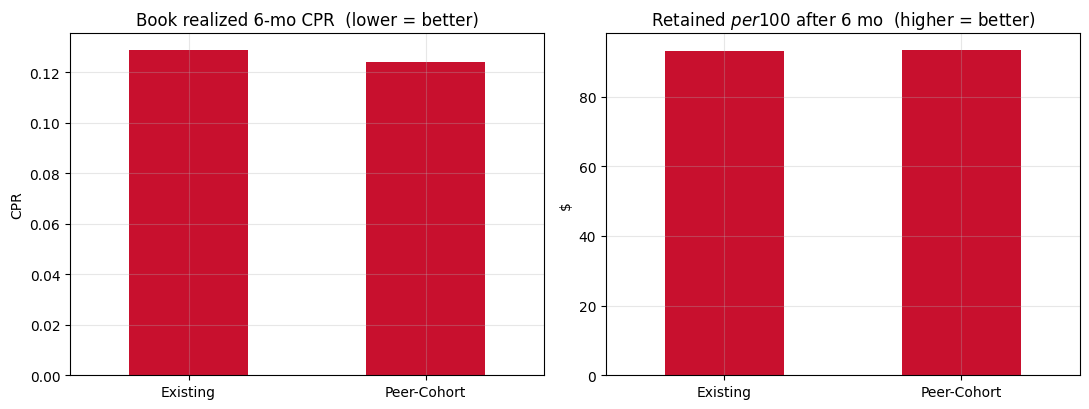

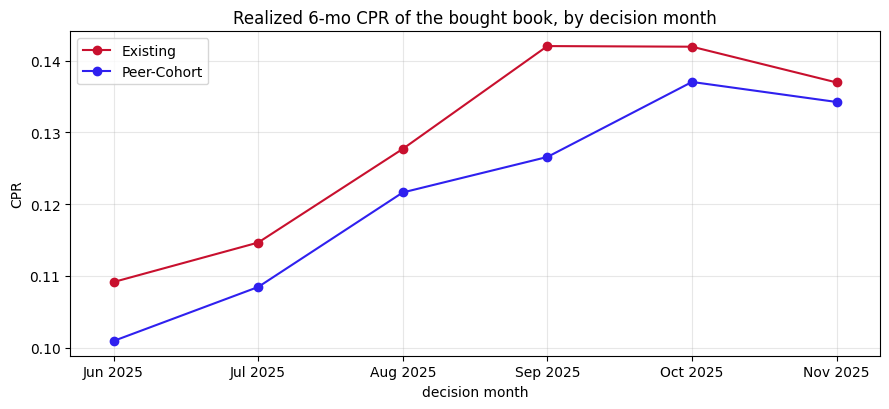

In [34]:
piv     = books.pivot(index='T', columns='policy', values='book_cpr')
piv_ret = books.pivot(index='T', columns='policy', values='retained')
win_rate = float((piv['Peer-Cohort'] < piv['Existing']).mean())

def _vw(pol, col):
    b = books[books.policy == pol]
    return wavg(b[col], b['bought'])

avg = pd.DataFrame({
    'Existing':    [_vw('Existing', 'book_cpr'),    _vw('Existing', 'retained') * 100],
    'Peer-Cohort': [_vw('Peer-Cohort', 'book_cpr'), _vw('Peer-Cohort', 'retained') * 100],
}, index=['Realized 6-mo CPR', 'Retained $ per $100'])
print("Dollar-weighted average across decision dates:")
display(avg.assign(Difference=lambda x: x['Peer-Cohort'] - x['Existing']).round(4))
print(f"\nWin-rate (months Peer-Cohort book prepaid slower): {win_rate:.0%} of {len(piv)} months")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
avg.loc[['Realized 6-mo CPR']].T.plot(kind='bar', ax=ax[0], legend=False, color=['#C8102E', '#2F20EF'])
ax[0].set_title("Book realized 6-mo CPR  (lower = better)"); ax[0].set_ylabel("CPR")
ax[0].set_xticklabels(['Existing', 'Peer-Cohort'], rotation=0)
avg.loc[['Retained $ per $100']].T.plot(kind='bar', ax=ax[1], legend=False, color=['#C8102E', '#2F20EF'])
ax[1].set_title("Retained $ per $100 after 6 mo  (higher = better)"); ax[1].set_ylabel("$")
ax[1].set_xticklabels(['Existing', 'Peer-Cohort'], rotation=0)
plt.tight_layout(); plt.show()

# month-by-month — plotted on a CATEGORICAL x-axis (fixes the date-axis artifact that
# used to show one extra month past DECISION_END).
labels = [pd.Timestamp(t).strftime('%b %Y') for t in piv.index]
axm = plt.subplots(figsize=(9, 4.2))[1]
axm.plot(range(len(piv)), piv['Existing'].values,    marker='o', color='#C8102E', label='Existing')
axm.plot(range(len(piv)), piv['Peer-Cohort'].values, marker='o', color='#2F20EF', label='Peer-Cohort')
axm.set_xticks(range(len(piv))); axm.set_xticklabels(labels, rotation=0)
axm.set_xlim(-0.3, len(piv) - 0.7)
axm.set_title("Realized 6-mo CPR of the bought book, by decision month")
axm.set_ylabel("CPR"); axm.set_xlabel("decision month"); axm.legend()
plt.tight_layout(); plt.show()

## 8. Result B — where the two scores **disagree**  *(deck Slide 5, context)*

* **Hidden risk** — Peer-Cohort flags Unfavourable, Existing did not → want it to prepay
  *faster* than the portfolio.
* **False alarm** — Existing flagged, Peer-Cohort cleared → want it *slower*.

,Group,RealizedCPR,Clients,ClientMonths,Volume
0,Portfolio average,13.3%,740,3636,"$23,576,940,245"
1,"Hidden risk (Peer-Cohort flags, Existing missed)",12.6%,225,735,"$8,682,553,699"
2,"False alarm (Existing flags, Peer-Cohort clea...",13.6%,99,238,"$727,795,711"
3,Both flag Unfavourable,16.5%,209,697,"$5,870,169,703"


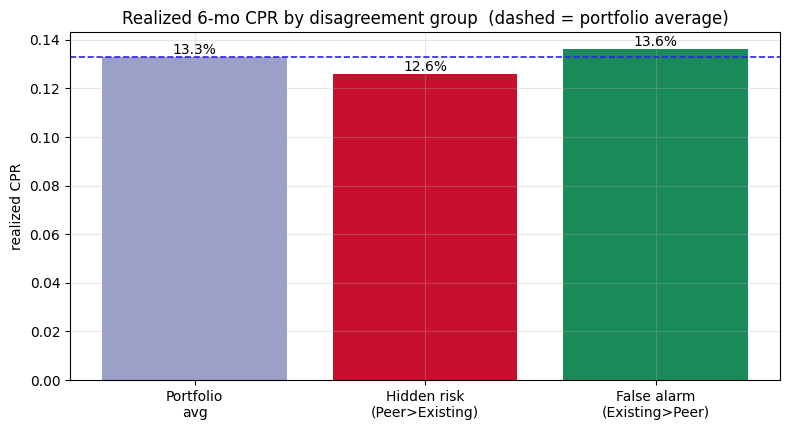

In [35]:
port_cpr = wavg(rows['cpr'], rows['buy'])
hr = rows[(rows.seg_peer == 'Unfavourable') & (rows.seg_existing != 'Unfavourable')]
fa = rows[(rows.seg_existing == 'Unfavourable') & (rows.seg_peer != 'Unfavourable')]
ag = rows[(rows.seg_existing == 'Unfavourable') & (rows.seg_peer == 'Unfavourable')]

def grp(df, name):
    return dict(Group=name, RealizedCPR=wavg(df['cpr'], df['buy']),
                Clients=df['Client'].nunique(), ClientMonths=len(df), Volume=float(df['buy'].sum()))

summary_b = pd.DataFrame([
    dict(Group='Portfolio average', RealizedCPR=port_cpr, Clients=rows['Client'].nunique(),
         ClientMonths=len(rows), Volume=float(rows['buy'].sum())),
    grp(hr, 'Hidden risk  (Peer-Cohort flags, Existing missed)'),
    grp(fa, 'False alarm  (Existing flags, Peer-Cohort cleared)'),
    grp(ag, 'Both flag Unfavourable'),
])
disp = summary_b.copy()
disp['RealizedCPR'] = disp['RealizedCPR'].map('{:.1%}'.format)
disp['Volume'] = disp['Volume'].map('${:,.0f}'.format)
display(disp)

labels = ['Portfolio\navg', 'Hidden risk\n(Peer>Existing)', 'False alarm\n(Existing>Peer)']
vals   = [port_cpr, wavg(hr['cpr'], hr['buy']), wavg(fa['cpr'], fa['buy'])]
ax = plt.subplots(figsize=(8, 4.4))[1]
bars = ax.bar(labels, vals, color=['#9AA0C8', '#C8102E', '#1B8A5A'])
ax.axhline(port_cpr, color='#2F20EF', lw=1.2, ls='--')
ax.set_title("Realized 6-mo CPR by disagreement group  (dashed = portfolio average)")
ax.set_ylabel("realized CPR")
for b, v in zip(bars, vals):
    if pd.notna(v): ax.text(b.get_x() + b.get_width()/2, v, f"{v:.1%}", ha='center', va='bottom')
plt.tight_layout(); plt.show()

## 8b. Score-tag counts month-by-month

**Chart 1 — Disagreements:** how many clients did the two scores disagree on, and in which
direction?
* *Existing favours / Peer-Cohort flags* → the old score is letting risk through.
* *Peer-Cohort favours / Existing flags* → the old score may be raising a false alarm.

**Chart 2 — Agreements:** how many clients did both scores agree on?
* *Both cleared (Fav or Neutral)* — the consensus "buy" pool.
* *Both Unfavourable* — the consensus "caution" pool.


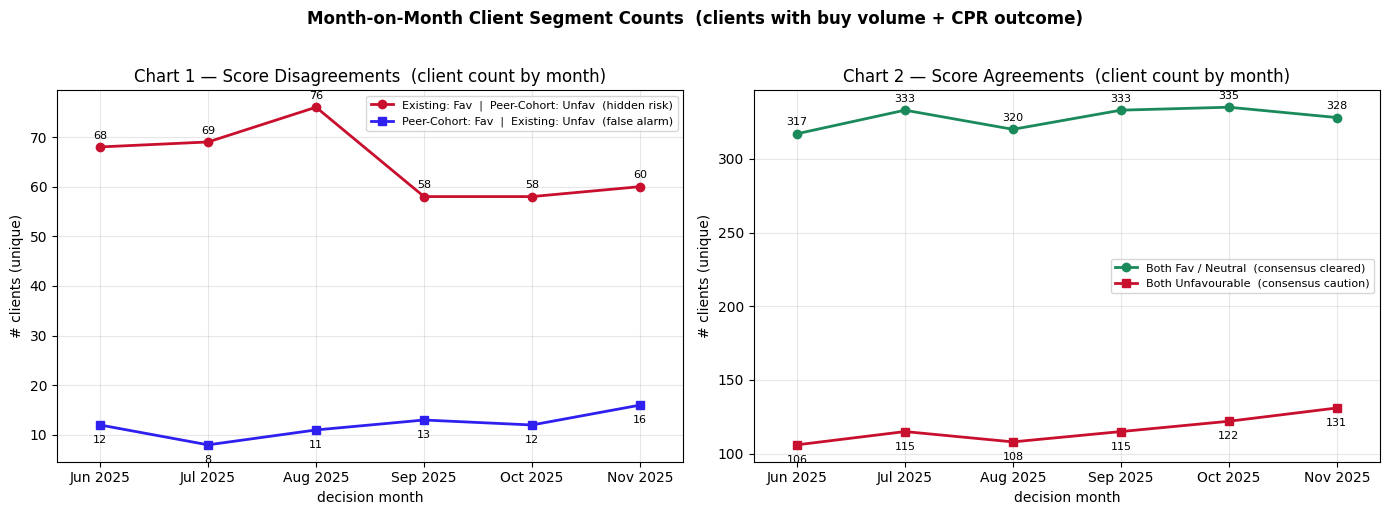

In [39]:
idx    = [pd.Timestamp(T) for T in DECISION_DATES]
xlabs  = [pd.Timestamp(t).strftime('%b %Y') for t in idx]
xpos   = list(range(len(idx)))

def _cnt(mask): return rows[mask].groupby('T')['Client'].nunique().reindex(idx, fill_value=0).values

# ── CHART 1: disagreements ────────────────────────────────────────────────────
c1a = _cnt((rows.seg_existing == 'Favourable')   & (rows.seg_peer == 'Unfavourable'))
c1b = _cnt((rows.seg_peer     == 'Favourable')   & (rows.seg_existing == 'Unfavourable'))

# ── CHART 2: agreements ───────────────────────────────────────────────────────
c2a = _cnt(rows.seg_existing.isin(['Favourable', 'Neutral']) & rows.seg_peer.isin(['Favourable', 'Neutral']))
c2b = _cnt((rows.seg_existing == 'Unfavourable') & (rows.seg_peer == 'Unfavourable'))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Chart 1
ax1.plot(xpos, c1a, marker='o', color='#C8102E', linewidth=2,
         label='Existing: Fav  |  Peer-Cohort: Unfav  (hidden risk)')
ax1.plot(xpos, c1b, marker='s', color='#2F20EF', linewidth=2,
         label='Peer-Cohort: Fav  |  Existing: Unfav  (false alarm)')
for x_, y_ in zip(xpos, c1a): ax1.annotate(str(y_), (x_, y_), textcoords='offset points', xytext=(0, 6), ha='center', fontsize=8)
for x_, y_ in zip(xpos, c1b): ax1.annotate(str(y_), (x_, y_), textcoords='offset points', xytext=(0, -13), ha='center', fontsize=8)
ax1.set_xticks(xpos); ax1.set_xticklabels(xlabs)
ax1.set_xlim(-0.4, len(idx) - 0.6)
ax1.set_title("Chart 1 — Score Disagreements  (client count by month)")
ax1.set_ylabel("# clients (unique)"); ax1.set_xlabel("decision month")
ax1.legend(fontsize=8)

# Chart 2
ax2.plot(xpos, c2a, marker='o', color='#1B8A5A', linewidth=2,
         label='Both Fav / Neutral  (consensus cleared)')
ax2.plot(xpos, c2b, marker='s', color='#C8102E', linewidth=2,
         label='Both Unfavourable  (consensus caution)')
for x_, y_ in zip(xpos, c2a): ax2.annotate(str(y_), (x_, y_), textcoords='offset points', xytext=(0, 6), ha='center', fontsize=8)
for x_, y_ in zip(xpos, c2b): ax2.annotate(str(y_), (x_, y_), textcoords='offset points', xytext=(0, -13), ha='center', fontsize=8)
ax2.set_xticks(xpos); ax2.set_xticklabels(xlabs)
ax2.set_xlim(-0.4, len(idx) - 0.6)
ax2.set_title("Chart 2 — Score Agreements  (client count by month)")
ax2.set_ylabel("# clients (unique)"); ax2.set_xlabel("decision month")
ax2.legend(fontsize=8)

plt.suptitle("Month-on-Month Client Segment Counts  (clients with buy volume + CPR outcome)",
             fontweight='bold', y=1.02)
plt.tight_layout(); plt.show()


## 9. Result C — the deciding test: **rate-SPREAD** control  *(deck Slide 5, hero)*

Bands by **Rate − Market_Rate** (not raw note rate). Within each spread band, do the loans
Peer-Cohort **flags** still prepay faster than the ones it **cleared**? If yes, the score is
catching real prepay risk relative to true peers — not just holding high-rate loans.

Within each rate-SPREAD band (Rate − Market_Rate): do Peer-Cohort's flagged loans still prepay faster than the ones it cleared?
[!] 97 client-rows have no Market_Rate → excluded from the band view.


,SpreadBand,Flagged_CPR,Cleared_CPR,Flagged_clients,Faster_by
0,≤ -1%,8.9%,7.9%,92,1.0%
1,-1–-0.5%,14.9%,13.0%,70,1.9%
2,-0.5–0%,16.7%,15.1%,101,1.5%
3,0–0.5%,17.7%,15.9%,60,1.8%
4,0.5–1.0%,14.1%,15.6%,9,-1.5%
5,1.0–1.5%,,13.1%,0,
6,1.5–2.0%,,,0,
7,2.0–2.5%,,,0,
8,2.5%+,,,0,


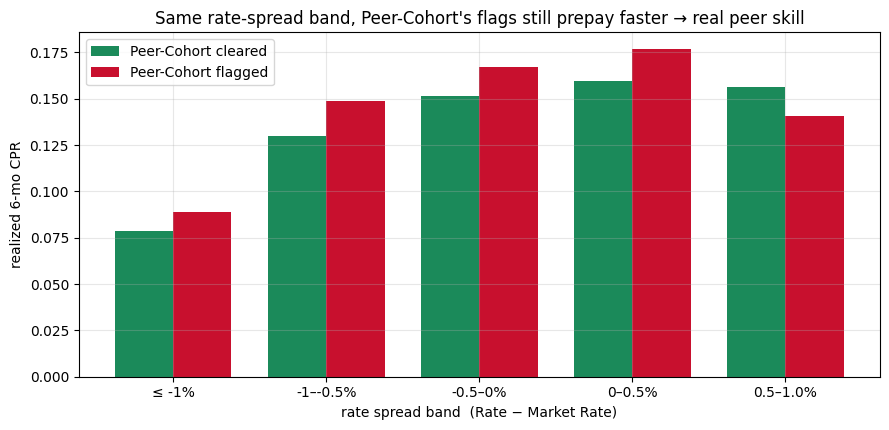

If the red bars sit above the green ones across bands, 'it's just high-rate loans' is ruled out.


In [36]:
rows['spread_band'] = pd.cut(rows['spread'], bins=SPREAD_BINS, labels=SPREAD_LABELS)
cleared = rows[rows.seg_peer != 'Unfavourable']
flagged = rows[(rows.seg_peer == 'Unfavourable') & (rows.seg_existing != 'Unfavourable')]

ctrl = []
for band in SPREAD_LABELS:
    f = flagged[flagged.spread_band == band]
    c = cleared[cleared.spread_band == band]
    ctrl.append(dict(SpreadBand=band,
                     Flagged_CPR=wavg(f['cpr'], f['buy']),
                     Cleared_CPR=wavg(c['cpr'], c['buy']),
                     Flagged_clients=f['Client'].nunique()))
ctrl = pd.DataFrame(ctrl)
ctrl['Faster_by'] = ctrl['Flagged_CPR'] - ctrl['Cleared_CPR']
show = ctrl.copy()
for c in ['Flagged_CPR', 'Cleared_CPR', 'Faster_by']:
    show[c] = show[c].map(lambda x: '' if pd.isna(x) else f'{x:.1%}')
n_missing = int(rows['spread'].isna().sum())
print("Within each rate-SPREAD band (Rate − Market_Rate): do Peer-Cohort's flagged loans "
      "still prepay faster than the ones it cleared?")
if n_missing:
    print(f"[!] {n_missing} client-rows have no Market_Rate → excluded from the band view.")
display(show)

plot = ctrl.dropna(subset=['Flagged_CPR', 'Cleared_CPR'])
if len(plot):
    x = np.arange(len(plot)); w = 0.38
    ax = plt.subplots(figsize=(9, 4.4))[1]
    ax.bar(x - w/2, plot['Cleared_CPR'], w, label='Peer-Cohort cleared', color='#1B8A5A')
    ax.bar(x + w/2, plot['Flagged_CPR'], w, label='Peer-Cohort flagged', color='#C8102E')
    ax.set_xticks(x); ax.set_xticklabels(plot['SpreadBand'])
    ax.set_ylabel("realized 6-mo CPR"); ax.set_xlabel("rate spread band  (Rate − Market Rate)")
    ax.set_title("Same rate-spread band, Peer-Cohort's flags still prepay faster → real peer skill")
    ax.legend(); plt.tight_layout(); plt.show()
print("If the red bars sit above the green ones across bands, 'it's just high-rate loans' is ruled out.")

## 10. Export the backtest pack (Excel)

In [37]:
pack = os.path.join(BACKTEST_DIR,
                    f"B2B_backtest_pack_{DECISION_START:%Y%m}_{DECISION_END:%Y%m}.xlsx")
with pd.ExcelWriter(pack, engine='xlsxwriter') as xl:
    books.round(6).to_excel(xl, sheet_name='book_by_month', index=False)
    avg.round(6).to_excel(xl, sheet_name='headline_avg')
    summary_b.round(6).to_excel(xl, sheet_name='disagreement_groups', index=False)
    ctrl.round(6).to_excel(xl, sheet_name='rate_spread_control', index=False)
    rows.drop(columns=['spread_band']).round(6).to_excel(xl, sheet_name='client_rows', index=False)
print("Backtest pack saved:", pack)

Backtest pack saved: E:\Development\Shashi\B2B-Pricing-Model\Cohort_Analysis\B2B_backtest\B2B_backtest_pack_202506_202511.xlsx


## 11. Plain-English summary  *(auto-generated from the numbers above)*

In [38]:
e_cpr, p_cpr = _vw('Existing', 'book_cpr'), _vw('Peer-Cohort', 'book_cpr')
e_ret, p_ret = _vw('Existing', 'retained') * 100, _vw('Peer-Cohort', 'retained') * 100
hr_cpr, fa_cpr = wavg(hr['cpr'], hr['buy']), wavg(fa['cpr'], fa['buy'])
bands_pass = int((ctrl['Faster_by'] > 0).sum()); bands_tot = int(ctrl['Faster_by'].notna().sum())

if p_cpr < e_cpr:
    verdict = ("Peer-Cohort wins on ABSOLUTE prepay — the toughest test for a peer score. "
               "Unambiguous.")
else:
    verdict = ("Peer-Cohort did not beat Existing on ABSOLUTE prepay. That is not a fail — "
               "absolute speed flatters the old rate-biased score. The rate-SPREAD control "
               "(Result C) is the deciding, peer-fair test.")

print("=" * 76)
print("B2B SCORE — BUY-OUTCOME BACKTEST  (judged by REAL prepayments)")
print(f"Decision dates: {DECISION_START} .. {DECISION_END}  |  watched {FORWARD_MONTHS} months forward")
print("=" * 76)
print(f'''
RESULT A — the bought book (same 20% aggregate $ cap, different targeting)
  Realized 6-mo CPR : Existing {e_cpr:6.2%}  vs  Peer-Cohort {p_cpr:6.2%}   (lower = better)
  Retained $/$100   : Existing {e_ret:6.2f}  vs  Peer-Cohort {p_ret:6.2f}   (higher = better)
  Win-rate (months Peer-Cohort prepaid slower): {win_rate:.0%}

RESULT B — where the scores disagree (real behaviour)
  Portfolio average realized CPR              : {port_cpr:6.2%}
  Hidden risk (Peer flags, Existing missed)  : {hr_cpr:6.2%}   -> want ABOVE portfolio
  False alarm (Existing flags, Peer cleared) : {fa_cpr:6.2%}   -> want BELOW portfolio

RESULT C — the deciding test: rate-SPREAD control (Rate − Market Rate)
  Flagged loans prepay faster than cleared in {bands_pass} of {bands_tot} spread bands
  (want flagged > cleared in every band -> real peer skill, not a high-rate tilt)

VERDICT: {verdict}
''')

B2B SCORE — BUY-OUTCOME BACKTEST  (judged by REAL prepayments)
Decision dates: 2025-06-30 .. 2025-11-30  |  watched 6 months forward

RESULT A — the bought book (same 20% aggregate $ cap, different targeting)
  Realized 6-mo CPR : Existing 12.89%  vs  Peer-Cohort 12.39%   (lower = better)
  Retained $/$100   : Existing  93.25  vs  Peer-Cohort  93.52   (higher = better)
  Win-rate (months Peer-Cohort prepaid slower): 100%

RESULT B — where the scores disagree (real behaviour)
  Portfolio average realized CPR              : 13.28%
  Hidden risk (Peer flags, Existing missed)  : 12.61%   -> want ABOVE portfolio
  False alarm (Existing flags, Peer cleared) : 13.63%   -> want BELOW portfolio

RESULT C — the deciding test: rate-SPREAD control (Rate − Market Rate)
  Flagged loans prepay faster than cleared in 4 of 5 spread bands
  (want flagged > cleared in every band -> real peer skill, not a high-rate tilt)

VERDICT: Peer-Cohort wins on ABSOLUTE prepay — the toughest test for a peer score. U